**Total water level (maakt .bzs file)**

In [100]:
##BZS##
import numpy as np
import pandas as pd
import rasterio.warp
import xarray as xr

# 1. Open het gedownloade NetCDF-bestand van Copernicus (Reanalysis 2024)
ds = xr.open_dataset(r'C:\Users\vanes\MDP\SFINCS\Total_water_level\reanalysis_waterlevel_10min_2024_02_v3.nc')

# 2. Definieer de exacte start- en eindtijd van de historische storm in 2024
model_tstart = pd.to_datetime('2024-02-05 00:00:00')
model_tstop = pd.to_datetime('2024-02-05 23:59:00')

# Selecteer de periode uit de dataset
tide_period = ds['waterlevel'].sel(
    time=slice(str(model_tstart), str(model_tstop))
)

# 3. Genereer de randpunten van de noordelijke rand opnieuw
bnd_row = 0
bnd_cols = range(mmax_coarse)

bnd_x, bnd_y = [], []
for c in bnd_cols:
  xw = xll_coarse + (c + 0.5) * dx_model
  yw = yll_coarse + ((nmax_coarse - 1 - bnd_row) + 0.5) * dy_model
  bnd_x.append(xw)
  bnd_y.append(yw)

# 4. Tijdstappen in seconden
num_steps = len(pd.date_range(start=model_tstart, end=model_tstop, freq='60s'))
time_seconds = np.linspace(
    0, (model_tstop - model_tstart).total_seconds(), num_steps
)
model_times = pd.date_range(start=model_tstart, end=model_tstop, periods=num_steps)

# 5. Loop door alle randpunten, converteer naar lat/lon en vind het dichtstbijzijnde station
water_levels_list = []

for xw, yw in zip(bnd_x, bnd_y):
  # Converteer model coördinaten (bijv. UTM / EPSG) naar Lat/Lon (EPSG:4326)
  lons, lats = rasterio.warp.transform(
      {'init': f'EPSG:{epsg_code}'}, {'init': 'EPSG:4326'}, [xw], [yw]
  )
  station_lon, station_lat = lons[0], lats[0]

  # Bereken dichtstbijzijnde station index in de dataset voor dit specifieke punt
  dist = (
      ds['station_x_coordinate'] - station_lon
  ) ** 2 + (ds['station_y_coordinate'] - station_lat) ** 2
  station_index = dist.argmin().item()

  # Pak de tijdreeks voor dit station en interpoleer naar de modeltijdstappen
  station_tide = tide_period.isel(stations=station_index)
  interp_tide = station_tide.interp(time=model_times, method='linear').values
  water_levels_list.append(interp_tide)

# 6. Combineer alles tot een matrix en schrijf weg naar sfincs.bzs
bzs_data = np.column_stack([time_seconds] + water_levels_list)
np.savetxt(r'C:\Users\vanes\MDP\SFINCS\sfincs_san_felipe\sfincs.bzs', bzs_data, fmt='%.3f', delimiter=' ')

print('sfincs.bzs succesvol aangemaakt op basis van de 2024 reanalysis data!')

sfincs.bzs succesvol aangemaakt op basis van de 2024 reanalysis data!


**Wind (maakt .wnd file)**

In [101]:
import cfgrib
import numpy as np
import pandas as pd
import rasterio.warp
import xarray as xr

# 1. Open het GRIB-bestand
ds = xr.open_dataset(
    r'C:\Users\vanes\MDP\CIEM3210 Coastal Engineering (202526 Q4) - 4292026 - 147 PM (1)\01_Waves\era5wind_2021_2026.grib',
    engine='cfgrib',
)

# 2. Definieer de exacte start- en eindtijd voor de SFINCS simulatie
model_tstart = pd.to_datetime('2024-02-05 00:00:00')
model_tstop = pd.to_datetime('2024-02-06 00:00:00')

# 3. Omrekenen van modelcoördinaten naar Lat/Lon (EPSG:4326) voor 1 representatief punt
xw = xll_coarse + 0.5 * dx_model
yw = yll_coarse + 0.5 * dy_model

lons, lats = rasterio.warp.transform(
    {'init': f'EPSG:{epsg_code}'}, {'init': 'EPSG:4326'}, [xw], [yw]
)
point_lon, point_lat = lons[0], lats[0]

# Selecteer het dichtstbijzijnde punt in het GRIB-raster
point_ds = ds.sel(longitude=point_lon, latitude=point_lat, method='nearest')

# 4. Platstrikken van valid_time en extractie van u10 en v10
# Als valid_time of time een 2D-matrix is, maken we er 1D-arrays van
if 'valid_time' in point_ds.coords:
    times_flat = pd.to_datetime(point_ds['valid_time'].values.flatten())
else:
    times_flat = pd.to_datetime(point_ds['time'].values.flatten())

u_flat = point_ds['u10'].values.flatten()
v_flat = point_ds['v10'].values.flatten()

# Bereken windsnelheid (m/s) en meteorologische windrichting (graden waar de wind VANDAAN komt)
wind_speed_flat = np.sqrt(u_flat**2 + v_flat**2)
wind_dir_flat = (270.0 - np.arctan2(v_flat, u_flat) * (180.0 / np.pi)) % 360.0

# Bundel in Pandas DataFrame om dubbele tijdstappen te verwijderen en te sorteren
df = pd.DataFrame({
    'valid_time': times_flat,
    'wind_speed': wind_speed_flat,
    'wind_dir': wind_dir_flat,
})
df = df.drop_duplicates(subset=['valid_time']).sort_values('valid_time')

# 5. Interpoleer de winddata naar de tijdsstappen van SFINCS (elke 60s)
num_steps = len(pd.date_range(start=model_tstart, end=model_tstop, freq='60s'))
time_seconds = np.linspace(
    0, (model_tstop - model_tstart).total_seconds(), num_steps
)
model_times = pd.date_range(start=model_tstart, end=model_tstop, periods=num_steps)

# Omzetten naar int64 nanoseconden voor np.interp
x_target = model_times.view('int64')
x_source = df['valid_time'].values.astype('datetime64[ns]').view('int64')

# Interpoleer snelheid
interp_speed = np.interp(x_target, x_source, df['wind_speed'].values)

# Interpoleer richting (gebruik unwrap voor de grens bij 0/360 graden)
dir_radians = np.unwrap(np.radians(df['wind_dir'].values))
interp_dir_rad = np.interp(x_target, x_source, dir_radians)
interp_dir = np.degrees(interp_dir_rad) % 360.0

# 6. Combineer tot exact 3 kolommen: [Tijd(s), Snelheid(m/s), Richting(deg)]
wnd_data = np.column_stack([time_seconds, interp_speed, interp_dir])

# Opslaan als sfincs.wnd
np.savetxt('sfincs_san_felipe/sfincs.wnd', wnd_data, fmt='%.3f', delimiter=' ')

print(
    f'sfincs.wnd succesvol opgeslagen met 3 kolommen! Shape: {wnd_data.shape}'
)

Ignoring index file 'C:\\Users\\vanes\\MDP\\CIEM3210 Coastal Engineering (202526 Q4) - 4292026 - 147 PM (1)\\01_Waves\\era5wind_2021_2026.grib.5b7b6.idx' incompatible with GRIB file


sfincs.wnd succesvol opgeslagen met 3 kolommen! Shape: (1441, 3)


**Precipitation (maakt .prcp file)**

In [102]:
import cfgrib
import numpy as np
import pandas as pd
import rasterio.warp
import xarray as xr

# 1. Open het GRIB-bestand
ds = xr.open_dataset(
    r'C:\Users\vanes\MDP\SFINCS\precipitation14_26.grib', engine='cfgrib'
)

# 2. Definieer start- en eindtijd van je SFINCS-simulatie
model_tstart = pd.to_datetime('2024-02-05 00:00:00')
model_tstop = pd.to_datetime('2024-02-06 00:00:00')

# 3. Kies het gewenste coördinaat (bijv. het centrum/rand van je SFINCS-grid)
# Als je modelcoördinaten gebruikt (bijv. UTM in meters), converteer deze naar Lat/Lon:
xw = xll_coarse + 0.5 * dx_model  # Voorbeeld punt
yw = yll_coarse + 0.5 * dy_model

lons, lats = rasterio.warp.transform(
    {'init': f'EPSG:{epsg_code}'}, {'init': 'EPSG:4326'}, [xw], [yw]
)
point_lon, point_lat = lons[0], lats[0]

# 4. Extract de data op de dichtstbijzijnde locatie
point_ds = ds.sel(longitude=point_lon, latitude=point_lat, method='nearest')

# 5. Converteer de 2D-tijdstructuur (time, step) naar een schone 1D-tijdserie
precip_var = 'tp' if 'tp' in ds else list(ds.data_vars.keys())[0]

# Flatten valid_time en neerslagdata
times_flat = pd.to_datetime(point_ds['valid_time'].values.flatten())
# Vermenigvuldig met 1000 om van meters (m) naar millimeter per uur (mm/h) te gaan
precip_flat = (point_ds[precip_var] * 1000.0).values.flatten()

# Maak een Pandas DataFrame om dubbele tijden te verwijderen en te sorteren
df = pd.DataFrame({'valid_time': times_flat, 'precip_mm_h': precip_flat})
df = df.drop_duplicates(subset=['valid_time']).sort_values('valid_time')

# 6. Interpoleer de neerslag naar de door SFINCS gewenste tijdsstap (bijv. elke 60 seconden)
num_steps = len(pd.date_range(start=model_tstart, end=model_tstop, freq='60s'))
time_seconds = np.linspace(
    0, (model_tstop - model_tstart).total_seconds(), num_steps
)
model_times = pd.date_range(start=model_tstart, end=model_tstop, periods=num_steps)

# Converteer datums naar gehele getallen (nanoseconden als int64) voor NumPy
x_target = model_times.view('int64')
x_source = df['valid_time'].values.astype('datetime64[ns]').view('int64')
y_source = df['precip_mm_h'].values

# Interpoleer de neerslagintensiteit
interp_precip = np.interp(
    x_target,
    x_source,
    y_source,
    left=0.0,
    right=0.0,  # Buiten het bereik wordt 0 mm/h aangehouden
)

# 7. Combineer tot 2 kolommen: [Tijd in sec, Intensiteit in mm/h]
precip_data = np.column_stack([time_seconds, interp_precip])

# 8. Opslaan als sfincs.prcp
np.savetxt('sfincs_san_felipe/sfincs.prcp', precip_data, fmt='%.6f', delimiter=' ')

print(
    f'sfincs.prcp succesvol opgeslagen met 2 kolommen! Shape: {precip_data.shape}'
)

sfincs.prcp succesvol opgeslagen met 2 kolommen! Shape: (1441, 2)


**Holy cell**

In [99]:
import os
import glob
import numpy as np
import rasterio
import rasterio.windows
import rasterio.transform
from rasterio.warp import transform
import rasterio.warp
from scipy.ndimage import zoom
from hydromt_sfincs import SfincsModel
import xarray as xr

# ==========================================
# 1. CONFIGURATIE: VEILIG GROF MODEL + FIJN SUBGRID
# ==========================================
bil_path = "702825741068_b/f16c26me.bil"
target_lat = 21.567176
target_lon = -88.231847

output_dir = "sfincs_san_felipe"
os.makedirs(output_dir, exist_ok=True)

# Celgrootte van het grove hoofdmodel (bijv. 25 of 50 meter)
dx_model = 5.0 
dy_model = 5.0

# Vaste, veilige subgrid resolutie (bijv. 1.0 meter per pixel)
fine_dx = 1.0
fine_dy = 1.0

# ==========================================
# 2. DEFINIEER HET SUBGRID BEREIK ROND SAN FELIPE
# ==========================================
print("Bezig met instellen van het fijnmazige subgrid...")

with rasterio.open(bil_path) as src_bil:
    xs, ys = transform({'init': 'EPSG:4326'}, src_bil.crs, [target_lon], [target_lat])
    x_target, y_target = xs[0], ys[0]
    
    # Kies een beheersbaar subgrid gebied rond San Felipe (bijv. 4 km x 4 km)
    box_size_m = 4000.0  
    nmax_fine = int(box_size_m / fine_dy)
    mmax_fine = int(box_size_m / fine_dx)
    
    x0 = x_target - (box_size_m / 2.0)
    y0_upper = y_target + (box_size_m / 2.0)
    
    fine_transform = rasterio.transform.from_origin(x0, y0_upper, fine_dx, fine_dy)

print(f"Fijn subgrid formaat (hdep): {mmax_fine} x {nmax_fine} pixels (resolutie: {fine_dx}m)")

# Bereken de afmetingen van het grove modelgrid
nmax_coarse = int((nmax_fine * fine_dy) / dy_model)
mmax_coarse = int((mmax_fine * fine_dx) / dx_model)
print(f"Grof rekenraster format (model): {mmax_coarse} x {nmax_coarse} cellen (dx = {dx_model}m)")

# ==========================================
# 3. BOUW DE FIJNE ELEVATIE (ELEV_FINE) OP
# ==========================================

# STAP 3A: Laad EERST de .bil basistegel in en pas 0 -> -2 toe
print("Inladen basistegel (.bil) en omzetten van 0 naar -2...")
with rasterio.open(bil_path) as src_bil:
    bil_resampled = np.empty((nmax_fine, mmax_fine), dtype=np.float32)
    rasterio.warp.reproject(
        source=rasterio.band(src_bil, 1),
        destination=bil_resampled,
        src_transform=src_bil.transform,
        src_crs=src_bil.crs,
        dst_transform=fine_transform,
        dst_crs=src_bil.crs,
        resampling=rasterio.enums.Resampling.bilinear
    )
    bil_resampled[bil_resampled < -900] = np.nan
    
    # Verander alle 0 waarden direct naar -2
    bil_resampled[bil_resampled == 0.0] = -2.0
    
    # Dit vormt nu de basisgrid
    elev_fine = bil_resampled

# STAP 3B: Laad PAS DAARNA de LiDAR bestanden in en leg ze over de basisgrid
# lidar_files = glob.glob("LIDAR data/**/MDE/*.tif", recursive=True)
lidar_files = glob.glob(r"C:\Users\vanes\MDP\SFINCS\LIDAR data\Combined_GPS_interpolated.tif", recursive=True)
print(f"Gevonden LiDAR bestanden voor subgrid: {len(lidar_files)}")

hardcoded_epsg = 32616 
target_crs = rasterio.crs.CRS.from_epsg(hardcoded_epsg)

for lidar_path in lidar_files:
    with rasterio.open(lidar_path) as lidar_src:
        lidar_resampled = np.empty((nmax_fine, mmax_fine), dtype=np.float32)
        try:
            rasterio.warp.reproject(
                source=rasterio.band(lidar_src, 1),
                destination=lidar_resampled,
                src_transform=lidar_src.transform,
                src_crs=lidar_src.crs,
                dst_transform=fine_transform,
                dst_crs=target_crs,
                resampling=rasterio.enums.Resampling.bilinear
            )
            lidar_resampled[lidar_resampled < -900] = np.nan
            
            # Overschrijf de basis (.bil met -2) overal waar LiDAR geldige data heeft
            elev_fine = np.where(~np.isnan(lidar_resampled), lidar_resampled, elev_fine)
            print(f"Toegevoegd aan subgrid: {lidar_path}")
        except Exception as e:
            print(f"Fout bij verwerken {lidar_path}: {e}")

elev_fine = np.nan_to_num(elev_fine, nan=-1.0)

# ==========================================
# 4. BESTANDEN WEGSCHRIJVEN (.dep, .hdep & .msk)
# ==========================================
def write_arc_ascii(filepath, data, xll, yll, cell_size, nodata=-999.0):
    nrows, ncols = data.shape
    data_clean = np.nan_to_num(data, nan=nodata)
    header = f"ncols        {ncols}\nnrows        {nrows}\nxllcorner    {xll}\nyllcorner    {yll}\ncellsize     {cell_size}\nNODATA_value {nodata}"
    np.savetxt(filepath, data_clean, fmt="%.2f", header=header, comments="")

yll_fine = y0_upper - (nmax_fine * fine_dy)
xll_fine = x0

yll_coarse = y0_upper - (nmax_coarse * dy_model)
xll_coarse = x0

# 1. Sla sfincs_hdep.dep op MET header (fijn subgrid)
write_arc_ascii(os.path.join(output_dir, "sfincs_hdep.dep"), elev_fine, xll_fine, yll_fine, fine_dx)

# 2. Sla sfincs.dep op ZONDER header (grof hoofdmodel)
zoom_factor_r = nmax_coarse / nmax_fine
zoom_factor_c = mmax_coarse / mmax_fine
elev_coarse = zoom(elev_fine, (zoom_factor_r, zoom_factor_c), order=1)
np.savetxt(os.path.join(output_dir, "sfincs.dep"), elev_coarse, fmt="%.2f")

# 3. Masker op grof niveau
mask_coarse = np.ones((nmax_coarse, mmax_coarse), dtype=int)
mask_coarse[0, :] = 2       
np.savetxt(os.path.join(output_dir, "sfincs.msk"), mask_coarse, fmt="%d")

# ==========================================
# 5. RANDVOORWAARDEN & FORCINGS (GROF GRID)
# ==========================================
bnd_row = 0
bnd_cols = [0, mmax_coarse - 1] 

bnd_x, bnd_y = [], []
for c in bnd_cols:
    xw = xll_coarse + (c + 0.5) * dx_model
    yw = yll_coarse + ((nmax_coarse - 1 - bnd_row) + 0.5) * dy_model
    bnd_x.append(xw)
    bnd_y.append(yw)

bnd_data = np.column_stack((bnd_x, bnd_y))
np.savetxt(os.path.join(output_dir, "sfincs.bnd"), bnd_data, fmt="%.2f", delimiter=" ")

model_tstart = pd.to_datetime("2024-02-05 00:00:00")
model_tstop = pd.to_datetime("2024-02-05 23:59:00")
total_seconds = (model_tstop - model_tstart).total_seconds()
num_steps = len(pd.date_range(start=model_tstart, end=model_tstop, freq="60s"))
time_seconds = np.linspace(0, total_seconds, num_steps)
model_times = pd.date_range(start=model_tstart, end=model_tstop, periods=num_steps)

# water_stand = np.ones_like(time_seconds)  
# water_matrix = np.tile(water_stand[:, np.newaxis], (1, len(bnd_x)))
# bzs_data = np.column_stack((time_seconds, water_matrix))
# np.savetxt(os.path.join(output_dir, "sfincs.bzs"), bzs_data, fmt="%.3f", delimiter=" ")

spc_columns = [time_seconds]
for _ in range(len(bnd_x)):
    spc_columns.append(np.ones_like(time_seconds) * 1.269)  
    spc_columns.append(np.ones_like(time_seconds) * 5.795)   
    spc_columns.append(np.ones_like(time_seconds)*305)  

spc_data = np.column_stack(spc_columns)
np.savetxt(os.path.join(output_dir, "sfincs.spc"), spc_data, fmt="%.3f", delimiter=" ")

precip_intensity = np.ones_like(time_seconds) * 0
prcp_data = np.column_stack((time_seconds, precip_intensity))
np.savetxt(os.path.join(output_dir, "sfincs.prcp"), prcp_data, fmt="%.2f", delimiter=" ")

# wind_speed = np.zeros_like(time_seconds)
# wind_dir = np.zeros_like(time_seconds)         
# wnd_data = np.column_stack((time_seconds, wind_speed, wind_dir))
# np.savetxt(os.path.join(output_dir, "sfincs.wnd"), wnd_data, fmt="%.2f", delimiter=" ")

zsini_coarse = elev_coarse + 1.0

np.savetxt(os.path.join(output_dir, "sfincs.zsini"), zsini_coarse, fmt="%.2f")

# ==========================================
# 6. CONFIGURATIEBESTAND (.inp)
# ==========================================
with rasterio.open(bil_path) as src_bil:
    epsg_code = src_bil.crs.to_epsg() or 32616

inp_content = f"""# SFINCS configuration file - San Felipe model (Safe Subgrids Active)
theta       = 0.5
tref        = 20240205 000000
tstart      = 20240205 000000
tstop       = 20240205 235900
dtout       = 60.0
dx          = {dx_model}
dy          = {dy_model}
nmax        = {nmax_coarse}
mmax        = {mmax_coarse}
x0          = {xll_coarse}
y0          = {yll_coarse}
epsg        = {epsg_code}
inputformat = asc
depfile     = sfincs.dep
hdepfile    = sfincs_hdep.dep
mskfile     = sfincs.msk
bndfile     = sfincs.bnd
bzsfile     = sfincs.bzs
wndfile     = sfincs.wnd
spcfile     = sfincs.spc
precipfile  = sfincs.prcp
zsfile      = sfincs.zsini
"""

with open(os.path.join(output_dir, "sfincs.inp"), "w") as f:
    f.write(inp_content.strip())

print("Veilige subgrid bestanden succesvol gegenereerd in:", output_dir)

Bezig met instellen van het fijnmazige subgrid...
Fijn subgrid formaat (hdep): 4000 x 4000 pixels (resolutie: 1.0m)
Grof rekenraster format (model): 800 x 800 cellen (dx = 5.0m)
Inladen basistegel (.bil) en omzetten van 0 naar -2...
Gevonden LiDAR bestanden voor subgrid: 1
Toegevoegd aan subgrid: C:\Users\vanes\MDP\SFINCS\LIDAR data\Combined_GPS_interpolated.tif
Veilige subgrid bestanden succesvol gegenereerd in: sfincs_san_felipe


## proberen van SWAN-SFINCS ##

In [9]:
import xarray as ds

# Open het NetCDF-bestand
data = ds.open_dataset(r'C:\Users\vanes\MDP\SFINCS\sfincs_san_felipe\swan_wave_grid.nc')

# Bekijk de meta-data, variabelen en dimensies
print(data)

<xarray.Dataset> Size: 938kB
Dimensions:  (y: 224, x: 348)
Coordinates:
  * y        (y) float32 896B 21.5 21.5 21.51 21.51 ... 22.09 22.09 22.1 22.1
  * x        (x) float32 1kB -88.65 -88.65 -88.64 ... -87.66 -87.65 -87.65
Data variables:
    hs       (y, x) float32 312kB ...
    tp       (y, x) float32 312kB ...
    dir      (y, x) float32 312kB ...


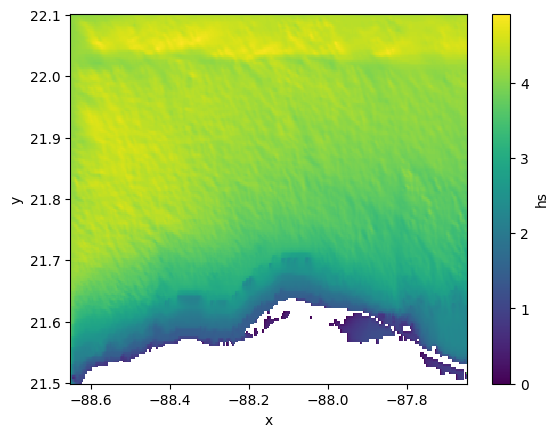

In [10]:
import matplotlib.pyplot as plt

# Voorbeeld: plot een variabele als de golfhoogte 'hs' aanwezig is
data['hs'].plot()
plt.show()

Inlezen van SFINCS resultaten uit: sfincs_san_felipe\sfincs_map.nc


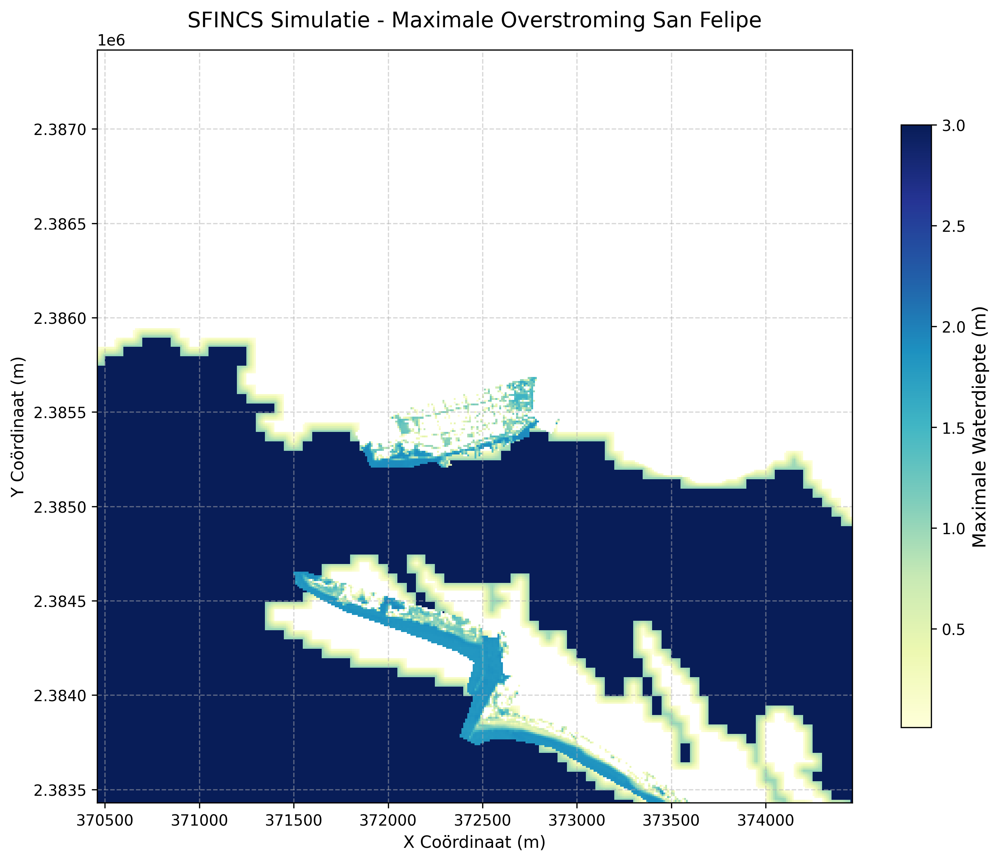

Plot succesvol opgeslagen als: sfincs_san_felipe\sfincs_max_waterdepth.png


In [62]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. INLEZEN VAN SFINCS RESULTATEN
# ==========================================
output_dir = "sfincs_san_felipe"
nc_file = os.path.join(output_dir, "sfincs_map.nc")

if not os.path.exists(nc_file):
    if os.path.exists("sfincs_map.nc"):
        nc_file = "sfincs_map.nc"
    else:
        raise FileNotFoundError(f"Kan {nc_file} niet vinden. Run eerst het SFINCS-model!")

print(f"Inlezen van SFINCS resultaten uit: {nc_file}")
ds = xr.open_dataset(nc_file)

# Selecteer variabele (voorkeur voor 'h' = waterdiepte, anders 'zs' = waterstand)
if 'h' in ds:
    var_name = 'h'
    label_text = "Maximale Waterdiepte (m)"
elif 'zs' in ds:
    var_name = 'zs'
    label_text = "Waterstand (m)"
else:
    var_name = list(ds.data_vars.keys())[0]
    label_text = var_name

data = ds[var_name]
x = ds['x'].values
y = ds['y'].values

# Bereken de maximale waarde per cel over de gehele tijdsduur (Max Inundation)
max_data = data.max(dim='time').values

# Maskeer droge cellen / heel dunne waterlaagjes (< 1 cm)
masked_data = np.where(max_data > 0.01, max_data, np.nan)

# ==========================================
# 2. PLOT OPBOOUWEN EN WEGSCHRIJVEN
# ==========================================
plt.figure(figsize=(10, 8), dpi=300)
ax = plt.subplot(1, 1, 1)

# Plot het 2D raster
pcm = ax.pcolormesh(
    x, y, masked_data,
    cmap="YlGnBu",      # Blauw-groene kleurenschaal voor water
    vmin=0.01,
    vmax=np.nanmax(masked_data),
    shading="auto"
)

# Kleurenbalak toevoegen
cbar = plt.colorbar(pcm, ax=ax, shrink=0.8)
cbar.set_label(label_text, fontsize=12)

# Opmaak
ax.set_title("SFINCS Simulatie - Maximale Overstroming San Felipe", fontsize=14, pad=15)
ax.set_xlabel("X Coördinaat (m)", fontsize=11)
ax.set_ylabel("Y Coördinaat (m)", fontsize=11)

# Corrigeer de spiegeling door te controleren op een 1D of 2D y-array
y_vals = y[:, 0] if y.ndim > 1 else y
if y_vals[0] > y_vals[-1]:
    ax.set_ylim(y_vals[-1], y_vals[0])
else:
    ax.set_ylim(y_vals[0], y_vals[-1])

ax.set_aspect('equal')
ax.grid(True, linestyle="--", alpha=0.5)

# Opslaan als afbeelding
output_plot = os.path.join(output_dir, "sfincs_max_waterdepth.png")
plt.tight_layout()
plt.savefig(output_plot)
plt.show()

print(f"Plot succesvol opgeslagen als: {output_plot}")

In [81]:
import os
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# Verhoog de limiet voor de zekerheid toch even
plt.rcParams['animation.embed_limit'] = 100.0

output_file = r"C:\Users\vanes\MDP\SFINCS\sfincs_san_felipe\sfincs_map.nc"

with nc.Dataset(output_file, 'r') as ds:
    times = ds.variables['time'][:]
    zs_time = ds.variables['h'][:, :, :] 

# 1. FILTER: Start pas vanaf 0.1 uur
start_index = np.argmax(times >= 0.1 * 3600)
times = times[start_index:]
zs_time = zs_time[start_index:, :, :]

# 2. REDUCEER FRAMES: Pak elk 10e frame
step = 10
times = times[::step]
zs_time = zs_time[::step, :, :]

elev_sfin = np.loadtxt("sfincs_san_felipe/sfincs.dep")

fig, ax = plt.subplots(figsize=(10, 10))

# 3. Achtergrond: Topografie (bewaar de image handle in 'im_elev')
im_elev = ax.imshow(elev_sfin, cmap="terrain", origin="upper", vmin=-5, vmax=5)

# Colorbar 1: Voor de bodem/dieptes (rechts of links geplaatst)
cbar_elev = fig.colorbar(im_elev, ax=ax, label="Bodemhoogte / Diepte t.o.v. MSL (m)", fraction=0.046, pad=0.04)

# 4. Waterlaag initialiseren vanaf het gefilterde startpunt
initial_data = zs_time[0, :, :]
water_init = np.where(initial_data > 0.1, initial_data, np.nan)
im_water = ax.imshow(water_init, cmap="Blues", origin="upper", vmin=0.1, vmax=2.0, alpha=0.8, animated=True)

# Colorbar 2: Voor de waterstand/diepte (geplaatst aan de andere kant of net iets verder)
# Om te zorgen dat ze elkaar niet bijten, kun je pad aanpassen of ze netjes naast elkaar zetten
cbar_water = fig.colorbar(im_water, ax=ax, label="Waterstand / Diepte (m)", fraction=0.046, pad=0.12)

t_start_hours = times[0] / 3600.0
title = ax.set_title(f"SFINCS constante Simulatie - Tijd: {t_start_hours:.2f} uur")
ax.set_xlabel("Grid X (cells)")
ax.set_ylabel("Grid Y (cells)")

def update(frame):
    data = zs_time[frame, :, :]
    water_plot = np.where(data > 0.1, data, np.nan) # Alleen filteren op waterdiepte/stand > 0.1m
    im_water.set_array(water_plot)
    
    t_hours = times[frame] / 3600.0
    title.set_text(f"SFINCS neerslag Simulatie - Tijd: {t_hours:.2f} uur")
    return im_water, title

ani = animation.FuncAnimation(fig, update, frames=len(times), interval=100, blit=True)

plt.close(fig)
HTML(ani.to_jshtml())